# 🎵🎬 DTW Audio-Video Synchronization

This notebook aligns a video's frames to a **new audio file** using **Dynamic Time Warping (DTW)**.

### Pipeline
```
input.mp4  ──► extract original audio
                      │
                      ├──► chroma features ──┐
new_audio.wav ──► chroma features ──────────┴──► DTW alignment path
                                                        │
                                          remap video frames
                                                        │
                                          mux with new audio
                                                        │
                                               output_synced.mp4
```

### Steps
1. Install dependencies
2. Upload your `input.mp4` and `new_audio.wav`
3. Run all cells in order


## 1 · Install dependencies

In [ ]:
%%capture
!pip install librosa dtw-python opencv-python-headless moviepy
!apt-get install -y ffmpeg

## 2 · Upload your files

Upload:
- **`input.mp4`** — your original video (with audio)
- **`new_audio.wav`** — the new audio you want the video synced to

Both files must contain the **same musical content** (or closely related versions) for DTW to work correctly.

In [ ]:
from google.colab import files

print("Upload input.mp4 and new_audio.wav")
uploaded = files.upload()
print("\nUploaded files:", list(uploaded.keys()))

Upload input.mp4 and new_audio.wav


Saving input.mp4 to input (1).mp4
Saving new_audio.wav to new_audio.wav

Uploaded files: ['input (1).mp4', 'new_audio.wav']


## 3 · Configuration

Edit these paths and parameters if needed.

In [ ]:
# ── File paths ──────────────────────────────────────────────
VIDEO_IN        = "input.mp4"       # original video
AUDIO_NEW       = "new_audio.wav"   # new audio to sync to
AUDIO_ORIG_WAV  = "orig_audio.wav"  # extracted from video (auto-generated)
VIDEO_RETIMED   = "retimed_silent.mp4"  # intermediate (no audio)
VIDEO_OUT       = "output_synced.mp4"   # final output

# ── Audio parameters ────────────────────────────────────────
SR  = 22050   # sample rate (Hz)
HOP = 512     # hop length for feature extraction (~23ms per frame)

# ── Feature type ────────────────────────────────────────────
# 'chroma'  → best for music (pitch-class content)
# 'mfcc'    → better for speech or percussive content
# 'onset'   → best for rhythm/beat alignment
FEATURE = "chroma"

# ── Smoothing ───────────────────────────────────────────────
# Number of frames to smooth the warp path (reduces jitter).
# 0 = no smoothing, 5-15 = gentle, 30+ = heavy
SMOOTH_WINDOW = 10

print("Configuration set.")

Configuration set.


## 4 · Imports

In [ ]:
import subprocess
import numpy as np
import librosa
import cv2
from dtw import dtw
from scipy.interpolate import interp1d
from scipy.ndimage import uniform_filter1d
import IPython.display as ipd
import matplotlib.pyplot as plt

print("All imports OK.")

All imports OK.


## 5 · Extract original audio from video

In [ ]:
def extract_audio_from_video(video_path, out_wav, sr=22050):
    """Extract mono audio from video using ffmpeg."""
    subprocess.run([
        "ffmpeg", "-y", "-i", video_path,
        "-ac", "1", "-ar", str(sr), out_wav
    ], check=True, capture_output=True)
    audio, _ = librosa.load(out_wav, sr=sr)
    print(f"  Original audio: {len(audio)/sr:.2f}s  ({len(audio)} samples)")
    return audio

print("Extracting original audio from video...")
audio_orig = extract_audio_from_video(VIDEO_IN, AUDIO_ORIG_WAV, sr=SR)

print("Loading new audio...")
audio_new, _ = librosa.load(AUDIO_NEW, sr=SR)
print(f"  New audio:      {len(audio_new)/SR:.2f}s  ({len(audio_new)} samples)")

# Quick listen
print("\n▶ Original audio:")
ipd.display(ipd.Audio(audio_orig, rate=SR))
print("▶ New audio:")
ipd.display(ipd.Audio(audio_new, rate=SR))

Extracting original audio from video...
  Original audio: 27.26s  (601088 samples)
Loading new audio...
  New audio:      14.66s  (323243 samples)

▶ Original audio:


▶ New audio:


## 6 · Compute audio features

Computing 'chroma' features...
  Original: 1175 frames
  New:      632 frames


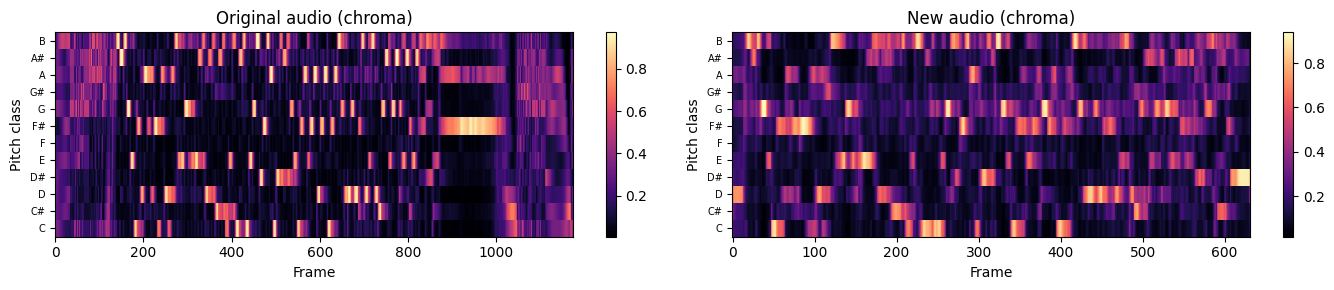

In [ ]:
def compute_features(audio, sr, hop, feature_type="chroma"):
    """
    Extract time-frequency features for DTW alignment.

    Returns array of shape (n_frames, n_features).
    """
    if feature_type == "chroma":
        feat = librosa.feature.chroma_cqt(y=audio, sr=sr, hop_length=hop)
    elif feature_type == "mfcc":
        feat = librosa.feature.mfcc(y=audio, sr=sr, hop_length=hop, n_mfcc=20)
    elif feature_type == "onset":
        env = librosa.onset.onset_strength(y=audio, sr=sr, hop_length=hop)
        feat = env[np.newaxis, :]   # shape (1, n_frames)
    else:
        raise ValueError(f"Unknown feature type: {feature_type}")

    # L2-normalise each frame for robustness to volume differences
    norms = np.linalg.norm(feat, axis=0, keepdims=True) + 1e-8
    feat = feat / norms

    return feat.T   # (n_frames, n_features)

print(f"Computing '{FEATURE}' features...")
feat_orig = compute_features(audio_orig, SR, HOP, FEATURE)
feat_new  = compute_features(audio_new,  SR, HOP, FEATURE)

print(f"  Original: {feat_orig.shape[0]} frames")
print(f"  New:      {feat_new.shape[0]} frames")

# Visualise chroma
if FEATURE == "chroma":
    fig, axes = plt.subplots(1, 2, figsize=(14, 3))
    for ax, feat, title in zip(axes,
                                [feat_orig.T, feat_new.T],
                                ["Original audio (chroma)", "New audio (chroma)"]):
        im = ax.imshow(feat, aspect="auto", origin="lower",
                       cmap="magma", interpolation="nearest")
        ax.set_title(title)
        ax.set_xlabel("Frame")
        ax.set_ylabel("Pitch class")
        ax.set_yticks(range(12))
        ax.set_yticklabels(['C','C#','D','D#','E','F',
                             'F#','G','G#','A','A#','B'], fontsize=7)
        plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

## 7 · Run DTW alignment

Running DTW...  (may take a moment for long audio)
  Alignment path length: 1556 steps
  Normalised DTW distance: 0.4277


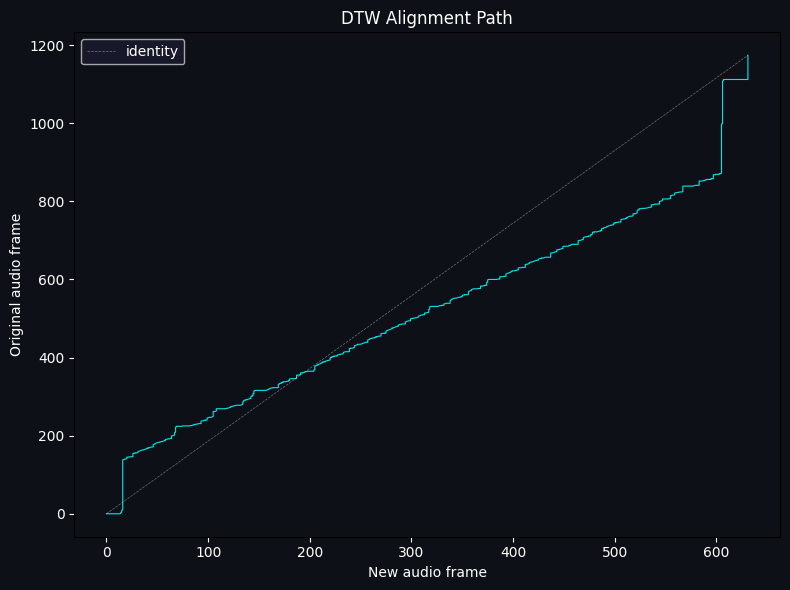

In [ ]:
print("Running DTW...  (may take a moment for long audio)")

alignment = dtw(
    feat_orig,          # query  (original audio frames)
    feat_new,           # reference (new audio frames)
    dist_method="euclidean",
    keep_internals=True
)

idx_orig = alignment.index1   # frame indices in original
idx_new  = alignment.index2   # corresponding frame indices in new audio

print(f"  Alignment path length: {len(idx_orig)} steps")
print(f"  Normalised DTW distance: {alignment.normalizedDistance:.4f}")

# Visualise alignment path
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(idx_new, idx_orig, color="cyan", lw=0.8, alpha=0.9)
ax.plot([0, max(idx_new)], [0, max(idx_orig)],
        color="white", lw=0.5, linestyle="--", alpha=0.4, label="identity")
ax.set_facecolor("#0d1117")
fig.patch.set_facecolor("#0d1117")
ax.set_xlabel("New audio frame", color="white")
ax.set_ylabel("Original audio frame", color="white")
ax.set_title("DTW Alignment Path", color="white")
ax.tick_params(colors="white")
ax.legend(facecolor="#1a1a2e", labelcolor="white")
plt.tight_layout()
plt.show()

## 8 · Build video frame remapping

  Video: 1920×1080  24.00 fps  582 frames
  Output frames needed: 351  (14.62s at 24.00 fps)


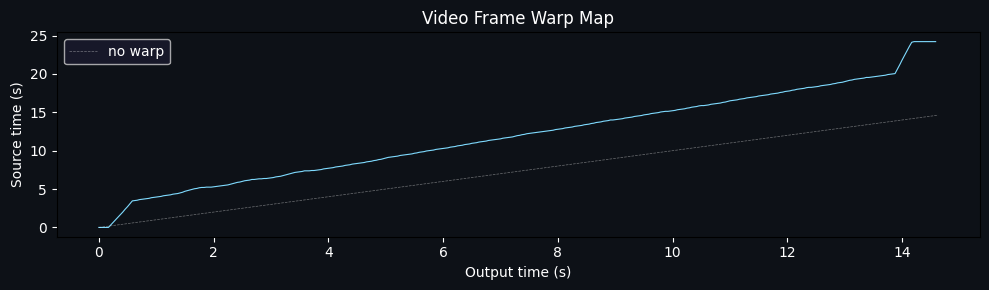

In [ ]:
# Get video properties
cap = cv2.VideoCapture(VIDEO_IN)
FPS            = cap.get(cv2.CAP_PROP_FPS)
TOTAL_FRAMES   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
WIDTH          = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT         = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

print(f"  Video: {WIDTH}×{HEIGHT}  {FPS:.2f} fps  {TOTAL_FRAMES} frames")

def build_frame_remap(idx_orig, idx_new, hop, sr, fps,
                      n_output_frames, smooth_window=0):
    """
    Given the DTW path (idx_orig, idx_new), produce an array
    source_frames[i] = which original frame to use for output frame i.
    """
    # Convert feature frame indices → seconds
    times_orig = idx_orig * hop / sr
    times_new  = idx_new  * hop / sr

    # Interpolator: new-audio time → original-video time
    remap_fn = interp1d(
        times_new, times_orig,
        kind="linear",
        bounds_error=False,
        fill_value=(times_orig[0], times_orig[-1])
    )

    # Output frame timestamps
    output_times  = np.arange(n_output_frames) / fps
    source_times  = remap_fn(output_times)

    # Optionally smooth to reduce jitter
    if smooth_window > 1:
        source_times = uniform_filter1d(source_times, size=smooth_window)

    source_frames = np.clip(
        np.round(source_times * fps).astype(int),
        0, TOTAL_FRAMES - 1
    )
    return source_frames

# Number of output frames = duration of new audio × FPS
n_output_frames = int(len(audio_new) / SR * FPS)
print(f"  Output frames needed: {n_output_frames}  "
      f"({n_output_frames/FPS:.2f}s at {FPS:.2f} fps)")

source_frames = build_frame_remap(
    idx_orig, idx_new,
    hop=HOP, sr=SR, fps=FPS,
    n_output_frames=n_output_frames,
    smooth_window=SMOOTH_WINDOW
)

# Visualise the warp
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(n_output_frames) / FPS,
        source_frames / FPS,
        color="#7fdbff", lw=0.8)
ax.plot([0, n_output_frames/FPS], [0, n_output_frames/FPS],
        color="white", lw=0.5, linestyle="--", alpha=0.4, label="no warp")
ax.set_facecolor("#0d1117")
fig.patch.set_facecolor("#0d1117")
ax.set_xlabel("Output time (s)", color="white")
ax.set_ylabel("Source time (s)", color="white")
ax.set_title("Video Frame Warp Map", color="white")
ax.tick_params(colors="white")
ax.legend(facecolor="#1a1a2e", labelcolor="white")
plt.tight_layout()
plt.show()

## 9 · Write retimed video

> ⚠️ For videos longer than ~3 minutes, the cell below may use significant RAM.
> If you hit memory limits, switch `USE_SEEK_MODE = True` (slower but memory-safe).

In [ ]:
USE_SEEK_MODE = False   # set True for long videos to save RAM

def retime_video_buffered(video_in, source_frames, video_out, fps, width, height):
    """Load all frames into RAM, then write remapped output. Fast."""
    cap = cv2.VideoCapture(video_in)
    print("  Reading all frames into memory...")
    all_frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        all_frames.append(frame)
    cap.release()
    print(f"  Loaded {len(all_frames)} frames.")

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    out    = cv2.VideoWriter(video_out, fourcc, fps, (width, height))
    for i, src in enumerate(source_frames):
        out.write(all_frames[src])
        if i % 200 == 0:
            print(f"  Writing frame {i}/{len(source_frames)}...", end="\r")
    out.release()
    print(f"\n  Done. Retimed video saved: {video_out}")


def retime_video_seek(video_in, source_frames, video_out, fps, width, height):
    """Seek frame-by-frame. Memory-safe but slower."""
    cap    = cv2.VideoCapture(video_in)
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    out    = cv2.VideoWriter(video_out, fourcc, fps, (width, height))
    prev_idx = -1
    frame_cache = {}
    for i, src in enumerate(source_frames):
        if src != prev_idx:
            cap.set(cv2.CAP_PROP_POS_FRAMES, src)
            ret, frame = cap.read()
            if not ret:
                frame = np.zeros((height, width, 3), dtype=np.uint8)
            frame_cache = frame
            prev_idx = src
        out.write(frame_cache)
        if i % 200 == 0:
            print(f"  Writing frame {i}/{len(source_frames)}...", end="\r")
    cap.release()
    out.release()
    print(f"\n  Done. Retimed video saved: {video_out}")


print(f"Writing retimed video (silent)...")
if USE_SEEK_MODE:
    retime_video_seek(VIDEO_IN, source_frames, VIDEO_RETIMED, FPS, WIDTH, HEIGHT)
else:
    retime_video_buffered(VIDEO_IN, source_frames, VIDEO_RETIMED, FPS, WIDTH, HEIGHT)

Writing retimed video (silent)...
  Reading all frames into memory...
  Loaded 582 frames.

  Done. Retimed video saved: retimed_silent.mp4


## 10 · Mux retimed video with new audio

In [ ]:
def mux_video_audio(video_path, audio_path, output_path):
    """Combine silent retimed video with new audio track using ffmpeg."""
    result = subprocess.run([
        "ffmpeg", "-y",
        "-i", video_path,
        "-i", audio_path,
        "-c:v", "libx264",
        "-preset", "fast",
        "-crf", "18",          # quality: 0 (lossless) – 51 (worst), 18 is excellent
        "-c:a", "aac",
        "-b:a", "192k",
        "-map", "0:v:0",
        "-map", "1:a:0",
        "-shortest",
        output_path
    ], check=True, capture_output=True)
    print(f"  Final video saved: {output_path}")

print("Muxing video + new audio...")
mux_video_audio(VIDEO_RETIMED, AUDIO_NEW, VIDEO_OUT)
print("✅ Done!")

Muxing video + new audio...
  Final video saved: output_synced.mp4
✅ Done!


## 11 · Preview & download

In [ ]:
from IPython.display import HTML
from base64 import b64encode

def show_video(path, max_mb=50):
    size_mb = __import__('os').path.getsize(path) / 1e6
    if size_mb > max_mb:
        print(f"File is {size_mb:.1f} MB — too large to embed. Download it below.")
        return
    with open(path, "rb") as f:
        data = b64encode(f.read()).decode()
    display(HTML(f"""
    <video width="720" controls>
      <source src="data:video/mp4;base64,{data}" type="video/mp4">
    </video>
    """))

print("▶ Preview of synced output:")
show_video(VIDEO_OUT)

▶ Preview of synced output:


In [ ]:
# Download the result
from google.colab import files
files.download(VIDEO_OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12 · (Optional) Diagnostics — alignment quality

Run this cell to inspect how much the frames were warped.

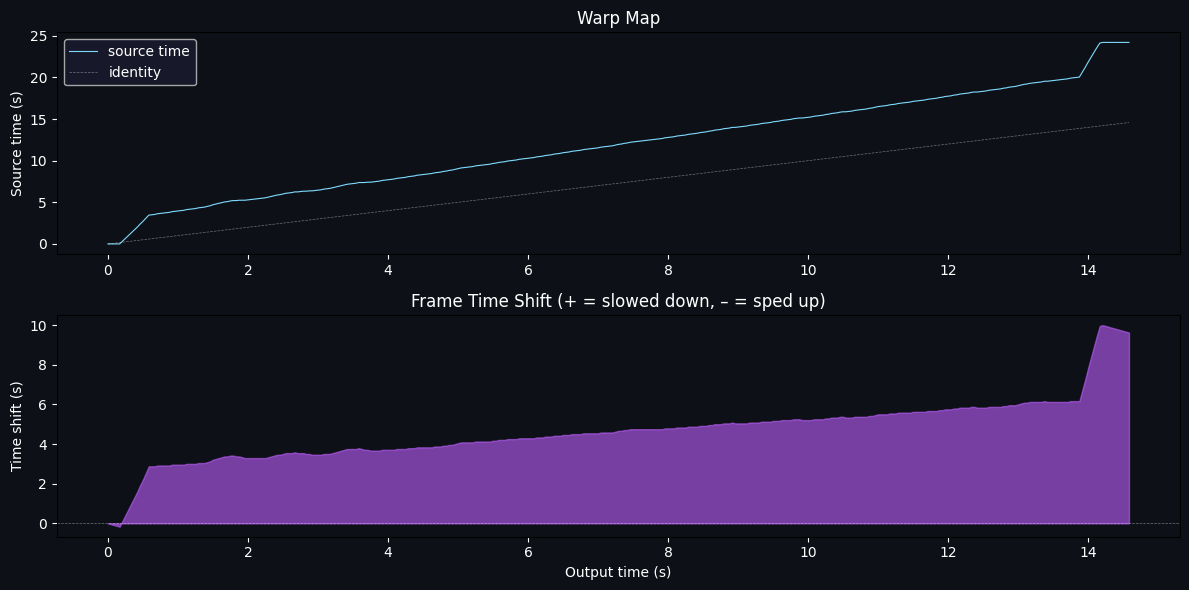

Max speed-up:   0.17s  (frames skipped)
Max slow-down:  10.00s  (frames repeated)
Mean |shift|:   4.66s


In [ ]:
output_times = np.arange(n_output_frames) / FPS
source_times = source_frames / FPS
warp_delta   = source_times - output_times   # positive = video slowed down

fig, axes = plt.subplots(2, 1, figsize=(12, 6),
                          facecolor="#0d1117")

ax = axes[0]
ax.set_facecolor("#0d1117")
ax.plot(output_times, source_times, color="#7fdbff", lw=0.8, label="source time")
ax.plot(output_times, output_times, color="white",  lw=0.5,
        linestyle="--", alpha=0.4, label="identity")
ax.set_ylabel("Source time (s)", color="white")
ax.set_title("Warp Map", color="white")
ax.tick_params(colors="white")
ax.legend(facecolor="#1a1a2e", labelcolor="white")

ax = axes[1]
ax.set_facecolor("#0d1117")
ax.fill_between(output_times, warp_delta, alpha=0.6, color="#bf5fff")
ax.axhline(0, color="white", lw=0.5, linestyle="--", alpha=0.4)
ax.set_xlabel("Output time (s)", color="white")
ax.set_ylabel("Time shift (s)", color="white")
ax.set_title("Frame Time Shift (+ = slowed down, – = sped up)", color="white")
ax.tick_params(colors="white")

plt.tight_layout()
plt.show()

print(f"Max speed-up:   {-warp_delta.min():.2f}s  (frames skipped)")
print(f"Max slow-down:  {warp_delta.max():.2f}s  (frames repeated)")
print(f"Mean |shift|:   {np.abs(warp_delta).mean():.2f}s")

---

## Notes & tips

| Situation | Recommendation |
|---|---|
| Music alignment | `FEATURE = "chroma"` |
| Speech / vocals | `FEATURE = "mfcc"` |
| Rhythm / percussion | `FEATURE = "onset"` |
| Jittery output | Increase `SMOOTH_WINDOW` (try 20–40) |
| Memory error | Set `USE_SEEK_MODE = True` |
| Poor alignment | Signals may be too different for DTW — check audio quality |
| Long videos | Consider [Sync Toolbox](https://github.com/meinardmueller/synctoolbox) with MrMsDTW for O(N) memory |

### Key concepts recap

- **DTW** finds the optimal monotonic path through a cost matrix between two feature sequences.
- **Chroma features** represent pitch-class content (C, C#, D, …) — robust to timbre and volume differences.
- **Frame remapping** uses the DTW path to answer: *"for each moment in the new audio, which video frame should be shown?"*
- **Smoothing** reduces the jitter caused by local DTW path irregularities.
